# DengueCast LK — An Ensemble Learning Early-Warning Dashboard for Weekly Dengue Cases in Sri Lanka

**Module:** Machine Learning — Hands-on Ensemble Learning Project (10%)
**Student:** Senanayaka S.M.C.S. (224176V)
**Submission:** Monday 23 November 2026

**Deliverables:** this notebook · Streamlit dashboard (`app.py`) · saved models (`models/*.pkl`) · GitHub repository · 3-minute video

> **AI usage:** GenAI (Claude, Anthropic) was used in this project. Details are in the **AI Usage Acknowledgment** section at the end of this notebook and in `README.md`.

### Contents
1. Problem and innovation
2. Data source
3. Setup and data loading
4. Data cleaning
5. Exploratory data analysis (EDA)
6. Feature engineering and time-based split
7. Evaluation method and metric choice
8. Baselines
9. Bagging — Random Forest and Bagged Decision Trees
10. Boosting — XGBoost, LightGBM, CatBoost
11. Stacking
12. Hybrid A — ARIMA + Random Forest
13. Hybrid B — Random Forest + ANN
14. Model comparison
15. Why the models behaved this way
16. Feature importance
17. Research reflection — RF vs gradient boosting, tabular vs image/text
18. Saving models and next-week early warning
19. Dashboard
20. Conclusion and limitations
21. AI Usage Acknowledgment
22. References

## 1. Problem and innovation

Dengue is the most common notifiable disease in Sri Lanka. 2026 is one of the worst years on record: floodwater left by
Cyclone Ditwah (late Nov–Dec 2025) and the south-west monsoon created many breeding sites, and the National Dengue
Control Unit reported more than 90,000 cases by mid-August 2026. Hospitals in Colombo, Gampaha, Kalutara, Matara and Kandy
came under strain.

Public health teams (MOH offices, PHIs) plan fogging, clean-up campaigns and hospital beds **one week at a time**,
but they mostly react to last week's numbers. A reliable 1-week-ahead forecast for each district can give them a few
extra days to act.

**Problem statement.** Using 20 years of official weekly dengue counts for Sri Lanka's 26 RDHS divisions, predict the
number of dengue cases in each division for the next week, compare bagging, boosting, stacking and hybrid ensembles,
and present the best forecasts in an early-warning dashboard.

**What is new / useful in this project**
- One model for **all 26 divisions** (a panel model). Small divisions such as Mullaitivu learn from patterns in large ones such as Colombo.
- Ensembles are compared on a real **outbreak year (2026)** that none of the models saw in training — a hard, honest test.
- The forecast is turned into a **risk level** (Low / Moderate / High / Very high) based on each division's own history, and the dashboard ranks divisions for next week.
- Besides MAE and RMSE, the models are judged on **outbreak-alert recall** — how many high-risk weeks they catch — because missing an outbreak week costs more than a false alarm.

## 2. Data source

| Item | Details |
|---|---|
| Original source | Weekly Epidemiological Reports (WER), Epidemiology Unit, Ministry of Health, Sri Lanka |
| Tidy version used | `srilanka_weekly_data` from the **denguedatahub** R package (T. S. Talagala, University of Sri Jayewardenepura) — https://github.com/thiyangt/denguedatahub |
| Coverage | 26 RDHS divisions (25 districts + Kalmunai), week 52 of 2006 to week 37 of 2026 (start date 7 Sep 2026) in the raw file; **used: 30 Dec 2006 – week starting 10 Aug 2026** |
| Granularity | One row per division per epidemiological week |
| Columns | `year`, `week`, `start.date`, `end.date`, `district`, `cases` |
| Size | 26,753 rows (raw) |
| How it was obtained | `download_data.py` downloads the `.rda` file from GitHub, reads it with `pyreadr` and saves `data/dengue_weekly_raw.csv` and `data/dengue_weekly_clean.csv` |

This is a **local, official Sri Lankan dataset** — not a foreign Kaggle dataset.

## 0. Running in Google Colab

Run the cell below first. In Colab it asks you to upload `DengueCast_LK_submission.zip` (or clones the GitHub repo if you
set `GITHUB_REPO`), unzips it, moves into the project folder and installs the missing libraries. On a local Jupyter
install it does nothing.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
GITHUB_REPO = ""   # optional, e.g. "https://github.com/<your-username>/denguecast-lk.git"

if IN_COLAB:
    if not os.path.exists("/content/denguecast/dengue_features.py"):
        if GITHUB_REPO:
            !git clone -q {GITHUB_REPO} /content/denguecast
        else:
            from google.colab import files
            print("Choose DengueCast_LK_submission.zip from your computer ...")
            uploaded = files.upload()
            zip_name = next(iter(uploaded))
            !unzip -q -o "{zip_name}" -d /content
    %cd /content/denguecast
    !pip install -q xgboost lightgbm catboost statsmodels pyreadr
print("Working folder:", os.getcwd())

Working folder: /home/claude/denguecast


## 3. Setup and data loading

In [2]:
# Run once in a new environment (Colab / fresh venv):
# !pip install pandas numpy scikit-learn xgboost lightgbm catboost statsmodels matplotlib seaborn joblib pyreadr

import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from statsmodels.tsa.arima.model import ARIMA

from dengue_features import build_features, FEATURES, NUM_FEATURES, CAT_FEATURES, TARGET
from hybrid_models import RFANNHybrid, CatBoostNative, make_preprocessor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("models", exist_ok=True); os.makedirs("results/figures", exist_ok=True)

# Chart colours (one fixed order, used everywhere)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

if not os.path.exists("data/dengue_weekly_clean.csv"):
    import subprocess; subprocess.run(["python", "download_data.py"], check=True)

raw = pd.read_csv("data/dengue_weekly_raw.csv")
df = pd.read_csv("data/dengue_weekly_clean.csv", parse_dates=["start_date", "end_date"])
print("Raw shape  :", raw.shape)
print("Clean shape:", df.shape)
df.head()

Raw shape  : (26753, 6)
Clean shape: (26624, 6)


,start_date,end_date,year,epi_week,district,cases
0,2006-12-30,2007-01-05,2007,1,Ampara,0
1,2007-01-06,2007-01-12,2007,2,Ampara,0
2,2007-01-13,2007-01-19,2007,3,Ampara,0
3,2007-01-20,2007-01-26,2007,4,Ampara,0
4,2007-01-27,2007-02-02,2007,5,Ampara,0


## 4. Data cleaning

Cleaning steps (done in `download_data.py`, checked here):
- Dates were stored in two formats (`12/23/2006` and `2026-09-07`) → parsed into one datetime column.
- The series begins with a single week in 2006 → dropped, so every division starts on 30 Dec 2006.
- Division names fixed (`Kalmune` → Kalmunai, `Hambanthota` → Hambantota, `NuwaraEliya` → Nuwara Eliya).
- **The last four weeks (from 17 Aug 2026) were removed as provisional.** Weekly reports are updated later when late notifications arrive. In those weeks the counts collapse in an impossible way (Gampaha 567 → 48, Kandy 288 → 10 in one week), so using them would teach the models a false drop and make the "next week" forecast wrong.
- A full week × division grid was built. Only **one** value was missing (Puttalam, one week) and it was filled by linear interpolation.
- No categorical text needs cleaning other than division names; there are no price strings or free-text fields.

In [3]:
print("Missing values per column:\n", df.isna().sum().to_dict())
print("Duplicate (week, division) rows:", df.duplicated(["start_date", "district"]).sum())
print("Divisions:", df["district"].nunique(), "| Weeks:", df["start_date"].nunique())
print("Date range:", df["start_date"].min().date(), "to", df["start_date"].max().date())
print("Negative counts:", (df["cases"] < 0).sum())
df["cases"].describe().round(1)

Missing values per column:
 {'start_date': 0, 'end_date': 0, 'year': 0, 'epi_week': 0, 'district': 0, 'cases': 0}
Duplicate (week, division) rows: 0
Divisions: 26 | Weeks: 1024
Date range: 2006-12-30 to 2026-08-10
Negative counts: 0


count    26624.0
mean        33.6
std         86.9
min          0.0
25%          2.0
50%          9.0
75%         30.0
max       2631.0
Name: cases, dtype: float64

## 5. Exploratory data analysis

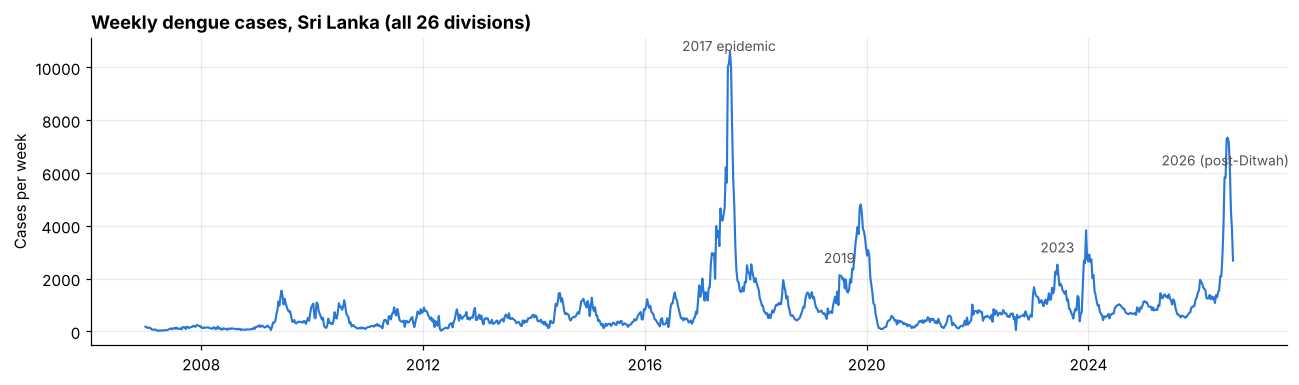

year
2007      6019
2008      5536
2009     26731
2010     25006
2011     21647
2012     23527
2013     22387
2014     35314
2015     22313
2016     35192
2017    174687
2018     51321
2019     94780
2020     32222
2021     20213
2022     31674
2023     70918
2024     53546
2025     49874
2026     92351


In [4]:
nat = df.groupby("start_date")["cases"].sum()
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(nat.index, nat.values, color=BLUE, lw=1.4)
for d, lab in [("2017-07-08", "2017 epidemic"), ("2019-07-06", "2019"), ("2023-06-10", "2023"), ("2026-06-20", "2026 (post-Ditwah)")]:
    ax.annotate(lab, (pd.Timestamp(d), nat.loc[nat.index[nat.index.get_indexer([pd.Timestamp(d)], method='nearest')[0]]]),
                xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color="#52514e")
ax.set_title("Weekly dengue cases, Sri Lanka (all 26 divisions)", loc="left", fontweight="bold")
ax.set_ylabel("Cases per week")
plt.tight_layout(); plt.savefig("results/figures/eda_national.png", dpi=150); plt.show()

yearly = df.groupby("year")["cases"].sum()
print(yearly.to_string())

**What this shows:** dengue in Sri Lanka comes in waves. Normal years have about 20,000–50,000 cases, but epidemic years
(2017, 2019, 2023 and 2026) are two to four times bigger. The 2017 peak was almost 9,000 cases in one week. 2026 is
already one of the largest years even though the data used here stops in mid-August. A model trained mostly on normal years must
still cope with these sudden jumps.

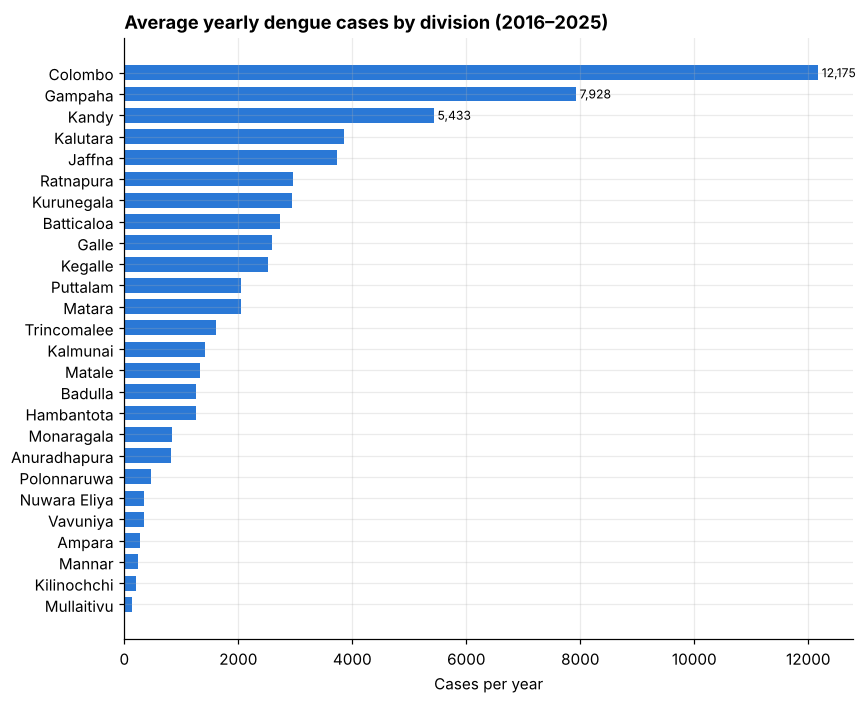

In [5]:
by_div = df[df["year"].between(2016, 2025)].groupby("district")["cases"].sum().sort_values() / 10
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(by_div.index, by_div.values, color=BLUE, height=0.7)
ax.set_title("Average yearly dengue cases by division (2016–2025)", loc="left", fontweight="bold")
ax.set_xlabel("Cases per year")
for y, v in enumerate(by_div.values):
    if v > 4000: ax.text(v, y, f" {v:,.0f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig("results/figures/eda_divisions.png", dpi=150); plt.show()

**What this shows:** the Western Province (Colombo, Gampaha, Kalutara) carries a large share of cases. Several northern and
eastern divisions have only a few cases a week. So the error scale differs a lot between divisions — one reason we model
`log(1 + cases)` instead of raw counts.

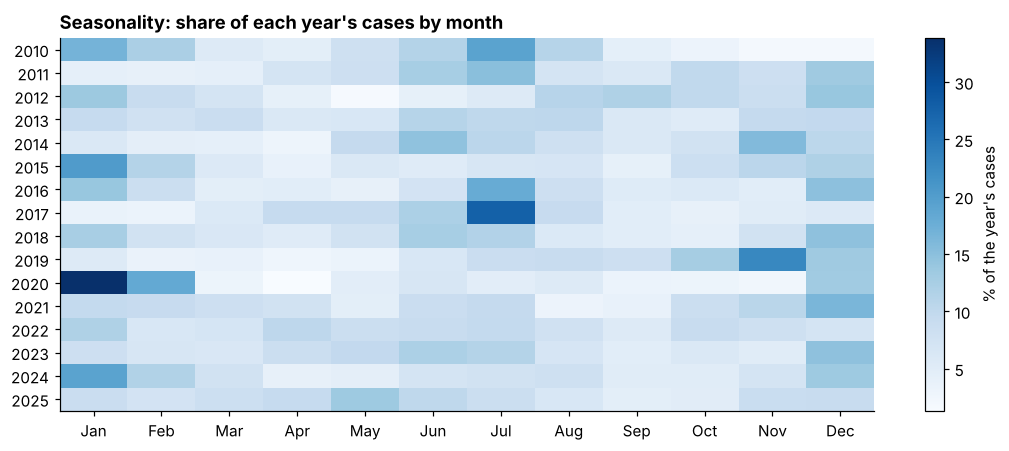

In [6]:
recent = df[df["year"].between(2010, 2025)].copy()
recent["month"] = recent["start_date"].dt.month
season = recent.groupby(["year", "month"])["cases"].sum().unstack()
season = season.div(season.sum(axis=1), axis=0) * 100           # % of the year's cases in each month
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(season.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(season))); ax.set_yticklabels(season.index); ax.grid(False)
plt.colorbar(im, ax=ax, label="% of the year's cases")
ax.set_title("Seasonality: share of each year's cases by month", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("results/figures/eda_seasonality.png", dpi=150); plt.show()

**What this shows:** most years have two peaks — **June–July** (after the south-west monsoon rains) and
**December–January** (north-east monsoon). This is why the features include the week of the year (as sine/cosine) and the
monsoon season.

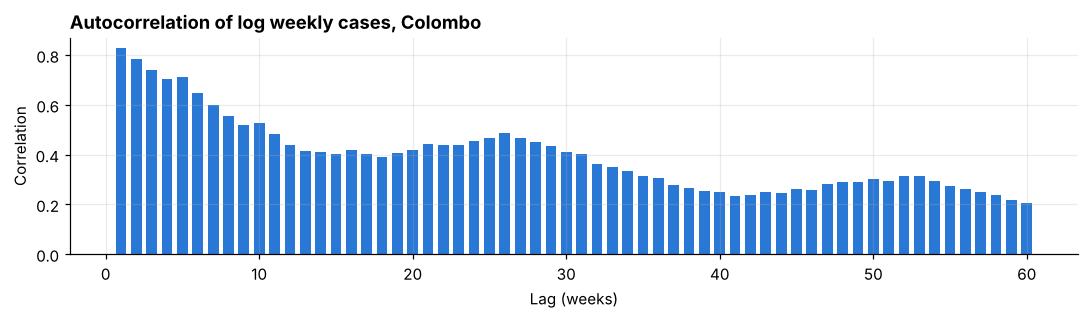

lag 1: 0.828 | lag 4: 0.703 | lag 52: 0.313


In [7]:
col = np.log1p(df[df["district"] == "Colombo"].set_index("start_date")["cases"])
lags = range(1, 61)
ac = [col.autocorr(l) for l in lags]
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(lags, ac, color=BLUE, width=0.7)
ax.set_title("Autocorrelation of log weekly cases, Colombo", loc="left", fontweight="bold")
ax.set_xlabel("Lag (weeks)"); ax.set_ylabel("Correlation")
plt.tight_layout(); plt.savefig("results/figures/eda_autocorr.png", dpi=150); plt.show()
print("lag 1:", round(ac[0], 3), "| lag 4:", round(ac[3], 3), "| lag 52:", round(ac[51], 3))

**What this shows:** this week's count is very strongly linked to last week's count (correlation above 0.9), and the link
fades slowly. There is also a small bump near lag 52 (same week last year). So recent lags are the most useful inputs, and the
same week last year adds a little seasonal memory.

## 6. Feature engineering and time-based split

All features use information available **at the end of the previous week** — nothing from the target week leaks in.

| Feature | Meaning |
|---|---|
| `lag1`–`lag4` | log(1+cases) 1 to 4 weeks ago |
| `lag52` | log(1+cases) in the same week last year |
| `roll_mean4`, `roll_mean8`, `roll_std4` | rolling mean / spread of the last 4 and 8 weeks |
| `trend` | `lag1 − lag2` (is the curve going up or down?) |
| `nat_lag1` | log national total last week (is the whole island in an outbreak?) |
| `week_sin`, `week_cos` | epidemiological week as a circle (week 52 sits next to week 1) |
| `season` | NE monsoon / 1st inter-monsoon / SW monsoon / 2nd inter-monsoon |
| `district` | RDHS division (categorical) |

**Split (no shuffling):** train = Jan 2008 – Dec 2023, test = Jan 2024 – mid-Aug 2026. The test period has two normal years
(2024, 2025) and the 2026 outbreak. Hyperparameter tuning uses `TimeSeriesSplit` inside the training period only.

In [8]:
feat = build_features(df)
feat = feat.dropna(subset=FEATURES).sort_values(["start_date", "district"]).reset_index(drop=True)

TEST_START = pd.Timestamp("2024-01-01")
train = feat[feat["start_date"] < TEST_START].reset_index(drop=True)
test = feat[feat["start_date"] >= TEST_START].reset_index(drop=True)
X_train, y_train = train[FEATURES], train[TARGET].astype(float)
X_test, y_test = test[FEATURES], test[TARGET].astype(float)
print(f"Train: {len(train):,} rows ({train.start_date.min().date()} to {train.start_date.max().date()})")
print(f"Test : {len(test):,} rows ({test.start_date.min().date()} to {test.start_date.max().date()})")
X_train.head(3)

Train: 21,736 rows (2007-12-29 to 2023-12-30)
Test : 3,536 rows (2024-01-06 to 2026-08-10)


,lag1,lag2,lag3,lag4,lag52,roll_mean4,roll_mean8,roll_std4,trend,nat_lag1,week_sin,week_cos,district,season
0,0.000000,0.000000,0.693147,0.00000,0.0,0.173287,0.173287,0.346574,0.000000,5.252273,0.120537,0.992709,Ampara,NE monsoon
1,2.944439,2.944439,2.564949,1.94591,0.0,2.599934,2.107651,0.471288,0.000000,5.252273,0.120537,0.992709,Anuradhapura,NE monsoon
2,1.791759,1.386294,0.693147,1.94591,0.0,1.454278,1.175079,0.559624,0.405465,5.252273,0.120537,0.992709,Badulla,NE monsoon


## 7. Evaluation method and metric choice

- **MAE** (mean absolute error, cases per division-week) — the main metric. It is easy to explain to a PHI ("on average we are off by *n* cases") and is not dominated by a few huge weeks.
- **RMSE** — punishes large misses, so it shows how well a model follows outbreak peaks.
- **R²** — share of the variation explained.
- **WAPE** (total absolute error ÷ total cases). Normal MAPE is not used because many small divisions have weeks with **zero** cases, which makes MAPE infinite.
- **Outbreak-alert Recall / Precision / F1.** A week is an *outbreak week* if its cases are above the division's 90th percentile in the training years. We check whether the forecast also crosses that line. **Recall matters most here**: a missed outbreak (false negative) is more harmful than an extra fogging round (false positive) — the same reason the lecture notebook tuned for recall.

All models predict `log(1 + cases)` and the prediction is converted back with `exp(x) − 1`, using `TransformedTargetRegressor`.

In [9]:
thr = train.groupby("district")["cases"].quantile([0.5, 0.75, 0.9, 0.95]).unstack()
thr.columns = ["p50", "p75", "p90", "p95"]
alert_line = test["district"].map(thr["p90"]).values
actual_alert = y_test.values >= alert_line
print(f"Outbreak weeks in test set: {actual_alert.sum()} of {len(actual_alert)} ({actual_alert.mean():.1%})")

results, preds, fit_times = [], {}, {}

def evaluate(name, y_pred, family, fit_time=np.nan):
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 0, None)
    pa = y_pred >= alert_line
    tp = (pa & actual_alert).sum()
    rec = tp / actual_alert.sum(); prec = tp / max(pa.sum(), 1)
    row = dict(model=name, family=family,
               MAE=mean_absolute_error(y_test, y_pred),
               RMSE=np.sqrt(mean_squared_error(y_test, y_pred)),
               R2=r2_score(y_test, y_pred),
               WAPE=np.abs(y_test - y_pred).sum() / y_test.sum() * 100,
               Alert_Recall=rec, Alert_Precision=prec,
               Alert_F1=2 * prec * rec / max(prec + rec, 1e-9),
               Train_time_s=fit_time)
    results[:] = [r for r in results if r["model"] != name] + [row]
    preds[name] = y_pred
    return pd.DataFrame([row]).round(3)

def log_model(regressor):
    return TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)

def timed_fit(model, X, y):
    t0 = time.perf_counter(); model.fit(X, y); return model, time.perf_counter() - t0

tscv = TimeSeriesSplit(n_splits=3)

Outbreak weeks in test set: 577 of 3536 (16.3%)


## 8. Baselines

A model is only useful if it beats simple rules. Two baselines:
- **Naive** — "next week = this week" (what a busy health office does by default).
- **Ridge regression** — a linear model on the same features (one-hot divisions, scaled inputs).

In [10]:
display(evaluate("Naive (last week)", np.expm1(test["lag1"]), "Baseline", 0.0))

ridge = log_model(Pipeline([("prep", make_preprocessor(scale=True)), ("model", Ridge(alpha=1.0))]))
ridge, t = timed_fit(ridge, X_train, y_train)
display(evaluate("Ridge regression", ridge.predict(X_test), "Baseline", t))

,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,Naive (last week),Baseline,16.008,53.502,0.786,29.736,0.698,0.705,0.701,0.0


,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,Ridge regression,Baseline,15.755,51.495,0.802,29.266,0.593,0.797,0.68,0.03


## 9. Bagging — Random Forest and Bagged Decision Trees

**Bagging (bootstrap aggregating)** trains many trees in parallel, each on a bootstrap sample (sampling with replacement),
and averages them. From the lecture, the variance of the average of *B* trees is

$$\text{Var} = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2$$

Increasing *B* removes the second term, but the first term stays if the trees are correlated (ρ). **Random Forest** lowers
ρ by letting each split look at only a random subset of features (`max_features`). Plain **Bagging** uses all features at
every split, so its trees tend to choose the same strong predictor (`lag1`) at the root and stay correlated.

The Random Forest is tuned with `GridSearchCV` (time-series CV, MAE scoring). We also report the **out-of-bag (OOB) score** —
each tree is checked on the ~37% of rows it did not see.

In [11]:
rf_search = GridSearchCV(
    log_model(Pipeline([("prep", make_preprocessor()),
                        ("model", RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=SEED))])),
    param_grid={"regressor__model__max_features": [0.33, 0.6],
                "regressor__model__min_samples_leaf": [3, 8]},
    scoring="neg_mean_absolute_error", cv=tscv, n_jobs=1)
t0 = time.perf_counter(); rf_search.fit(X_train, y_train); tune_rf = time.perf_counter() - t0
print("Best RF params:", rf_search.best_params_, "| CV MAE:", round(-rf_search.best_score_, 2), f"| tuning {tune_rf:.0f}s")
pd.DataFrame(rf_search.cv_results_)[["params", "mean_test_score"]].assign(mean_test_score=lambda d: -d.mean_test_score.round(2))

Best RF params: {'regressor__model__max_features': 0.6, 'regressor__model__min_samples_leaf': 8} | CV MAE: 14.4 | tuning 23s


,params,mean_test_score
0,"{'regressor__model__max_features': 0.33, 'regr...",15.09
1,"{'regressor__model__max_features': 0.33, 'regr...",15.03
2,"{'regressor__model__max_features': 0.6, 'regre...",14.46
3,"{'regressor__model__max_features': 0.6, 'regre...",14.40


In [12]:
best_rf = {k.split("__")[-1]: v for k, v in rf_search.best_params_.items()}
rf = log_model(Pipeline([("prep", make_preprocessor()),
                         ("model", RandomForestRegressor(n_estimators=200, oob_score=True, n_jobs=-1,
                                                         random_state=SEED, **best_rf))]))
rf, t = timed_fit(rf, X_train, y_train)
print("RF OOB R² (log scale):", round(rf.regressor_.named_steps["model"].oob_score_, 3))
display(evaluate("Random Forest", rf.predict(X_test), "Bagging", t))

bag = log_model(Pipeline([("prep", make_preprocessor()),
                          ("model", BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=best_rf["min_samples_leaf"]),
                                                     n_estimators=200, oob_score=True, n_jobs=-1, random_state=SEED))]))
bag, t = timed_fit(bag, X_train, y_train)
print("Bagging OOB R² (log scale):", round(bag.regressor_.named_steps["model"].oob_score_, 3))
display(evaluate("Bagging (Decision Trees)", bag.predict(X_test), "Bagging", t))

RF OOB R² (log scale): 0.837


,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,Random Forest,Bagging,15.269,53.171,0.788,28.364,0.617,0.777,0.688,5.536


Bagging OOB R² (log scale): 0.836


,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,Bagging (Decision Trees),Bagging,14.989,50.794,0.807,27.844,0.619,0.771,0.687,10.498


**Checking the ρ idea from the lecture.** Below we measure how correlated the individual trees are on the test set. If Random
Forest's feature sampling works, its trees should be less correlated than the plain Bagging trees.

In [13]:
def mean_tree_corr(fitted, n=40):
    m = fitted.regressor_.named_steps["model"]; Xt = fitted.regressor_.named_steps["prep"].transform(X_test)
    trees = m.estimators_[:n]
    P = np.vstack([tr.predict(Xt) for tr in trees])
    C = np.corrcoef(P); return C[np.triu_indices_from(C, 1)].mean()
rho_rf, rho_bag = mean_tree_corr(rf), mean_tree_corr(bag)
print(f"Mean correlation between trees — Random Forest: {rho_rf:.3f} | Bagging: {rho_bag:.3f}")

Mean correlation between trees — Random Forest: 0.927 | Bagging: 0.924


## 10. Boosting — XGBoost, LightGBM, CatBoost

Boosting trains trees **one after another**. Each new tree fits the errors (gradients of the loss) left by the trees before it:
$F_t(x) = F_{t-1}(x) + \eta\,h_t(x)$, where η is the learning rate. Bagging mainly reduces variance; boosting mainly reduces **bias**.

| Library | Key idea |
|---|---|
| **XGBoost** | second-order (gradient + Hessian) boosting with L1/L2 regularisation; level-wise trees |
| **LightGBM** | histogram binning + leaf-wise tree growth → very fast on large tables |
| **CatBoost** | ordered boosting and native handling of categorical columns (here `district`, `season` are given as raw text) |

XGBoost is tuned with `RandomizedSearchCV` (8 settings, time-series CV). LightGBM and CatBoost use standard settings with a
similar learning rate and tree size so the comparison is fair.

In [14]:
xgb_search = RandomizedSearchCV(
    log_model(Pipeline([("prep", make_preprocessor()),
                        ("model", XGBRegressor(tree_method="hist", random_state=SEED, n_jobs=2))])),
    param_distributions={"regressor__model__n_estimators": [300, 600],
                         "regressor__model__max_depth": [3, 4, 6],
                         "regressor__model__learning_rate": [0.03, 0.05, 0.1],
                         "regressor__model__subsample": [0.8, 1.0],
                         "regressor__model__colsample_bytree": [0.7, 1.0],
                         "regressor__model__min_child_weight": [1, 5]},
    n_iter=8, scoring="neg_mean_absolute_error", cv=tscv, random_state=SEED, n_jobs=1)
t0 = time.perf_counter(); xgb_search.fit(X_train, y_train); tune_xgb = time.perf_counter() - t0
best_xgb = {k.split("__")[-1]: v for k, v in xgb_search.best_params_.items()}
print("Best XGB params:", best_xgb, "| CV MAE:", round(-xgb_search.best_score_, 2), f"| tuning {tune_xgb:.0f}s")

xgb = log_model(Pipeline([("prep", make_preprocessor()),
                          ("model", XGBRegressor(tree_method="hist", random_state=SEED, n_jobs=2, **best_xgb))]))
xgb, t = timed_fit(xgb, X_train, y_train)
display(evaluate("XGBoost", xgb.predict(X_test), "Boosting", t))

Best XGB params: {'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.7} | CV MAE: 16.12 | tuning 8s


,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,XGBoost,Boosting,15.635,56.236,0.763,29.044,0.624,0.781,0.694,0.326


In [15]:
lgbm = log_model(Pipeline([("prep", make_preprocessor()),
                           ("model", LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31,
                                                   min_child_samples=20, subsample=0.8, subsample_freq=1,
                                                   colsample_bytree=0.8, random_state=SEED, n_jobs=2, verbose=-1))]))
lgbm, t = timed_fit(lgbm, X_train, y_train)
display(evaluate("LightGBM", lgbm.predict(X_test), "Boosting", t))

cat = log_model(CatBoostNative(iterations=800, depth=6, learning_rate=0.05, random_seed=SEED, thread_count=2))
cat, t = timed_fit(cat, X_train, y_train)
display(evaluate("CatBoost", cat.predict(X_test), "Boosting", t))

,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,LightGBM,Boosting,14.887,50.207,0.811,27.653,0.622,0.782,0.693,0.929


,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,CatBoost,Boosting,15.333,55.208,0.772,28.482,0.612,0.793,0.691,3.787


**Boosting step by step.** The curve below shows the test MAE of XGBoost as trees are added. It falls quickly at first —
each tree fixes part of the remaining error — and then flattens.

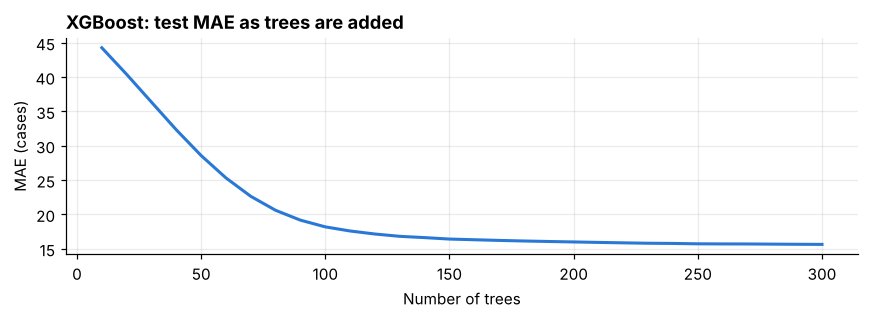

Test MAE after 100 / 200 / all trees: [18.19, 15.99, 15.64]


In [16]:
xm = xgb.regressor_.named_steps["model"]; Xt = xgb.regressor_.named_steps["prep"].transform(X_test)
steps = list(range(10, xm.n_estimators + 1, 10))
curve = [mean_absolute_error(y_test, np.expm1(xm.predict(Xt, iteration_range=(0, s)))) for s in steps]
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(steps, curve, color=BLUE, lw=2)
ax.set_title("XGBoost: test MAE as trees are added", loc="left", fontweight="bold")
ax.set_xlabel("Number of trees"); ax.set_ylabel("MAE (cases)")
plt.tight_layout(); plt.savefig("results/figures/xgb_staged.png", dpi=150); plt.show()
print("Test MAE after 100 / 200 / all trees:", [round(curve[steps.index(s)], 2) for s in (100, 200, steps[-1])])

## 11. Stacking

Stacking combines **different kinds** of models. The base learners — Random Forest (bagging), XGBoost, LightGBM, CatBoost
(boosting) and Ridge (linear) — make predictions, and a **meta-learner** learns how much to trust each one. The meta-learner is a
linear regression with non-negative weights, so the weights are easy to read. Base-model predictions for the meta-learner
come from 5-fold cross-validation (out-of-fold), so the meta-learner never sees predictions on rows the base model was trained on.

In [17]:
def inner(m): return m.regressor   # unfitted pipeline in log space
stack = log_model(StackingRegressor(
    estimators=[("rf", inner(rf)), ("xgb", inner(xgb)), ("lgbm", inner(lgbm)),
                ("cat", inner(cat)), ("ridge", inner(ridge))],
    final_estimator=LinearRegression(positive=True), cv=KFold(5), n_jobs=1, passthrough=False))
stack, t = timed_fit(stack, X_train, y_train)
w = stack.regressor_.final_estimator_.coef_
print("Meta-learner weights:", dict(zip(["RF", "XGB", "LGBM", "CatBoost", "Ridge"], np.round(w, 3))))
display(evaluate("Stacking (RF+XGB+LGBM+Cat+Ridge)", stack.predict(X_test), "Stacking", t))

Meta-learner weights: {'RF': np.float64(0.052), 'XGB': np.float64(0.131), 'LGBM': np.float64(0.274), 'CatBoost': np.float64(0.125), 'Ridge': np.float64(0.423)}


,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,Stacking (RF+XGB+LGBM+Cat+Ridge),Stacking,14.631,49.864,0.814,27.179,0.608,0.794,0.689,53.935


## 12. Hybrid A — ARIMA + Random Forest

The dashboard data is a time series, so the lecturer's suggested hybrid is **RF + ARIMA**:
1. For each division, an **ARIMA(p,1,q)** model is fitted on `log(1+cases)` from the training years. The order is chosen by AIC
   from (1,1,0), (1,1,1), (2,1,1), (2,1,2). ARIMA captures the linear, auto-correlated part of each division's curve.
2. The fitted ARIMA is run through the whole series with **fixed parameters** to produce honest one-step-ahead forecasts (no
   re-fitting on test data).
3. A **Random Forest** learns ARIMA's leftover error (residual) from the same features plus the ARIMA forecast. This is the
   non-linear part: monsoon effects, island-wide outbreaks, sudden jumps.
4. Final forecast = ARIMA forecast + RF residual forecast.

ARIMA on its own is also reported as a classic time-series benchmark.

In [18]:
t0 = time.perf_counter()
arima_fit, arima_pred_log = {}, []
for dname, g in df.sort_values("start_date").groupby("district"):
    dates = g["start_date"].values
    s = pd.Series(np.log1p(g["cases"].astype(float).values))      # plain integer index (weekly steps)
    s_train = s[dates < np.datetime64(TEST_START)]
    best = None
    for order in [(1, 1, 0), (1, 1, 1), (2, 1, 1), (2, 1, 2)]:
        try:
            r = ARIMA(s_train, order=order).fit()
            if best is None or r.aic < best.aic: best = r
        except Exception:
            pass
    applied = best.apply(s)                      # same parameters, run over full series
    arima_fit[dname] = {"order": best.model.order, "params": best.params, "result": applied}
    arima_pred_log.append(pd.DataFrame({"start_date": dates, "district": dname,
                                        "arima_log": applied.fittedvalues.values}))
arima_pred_log = pd.concat(arima_pred_log)
arima_time = time.perf_counter() - t0
print(f"Fitted {len(arima_fit)} ARIMA models in {arima_time:.0f}s")
print(pd.Series({k: str(v["order"]) for k, v in arima_fit.items()}).value_counts().to_string())

train_h = train.merge(arima_pred_log, on=["start_date", "district"], how="left")
test_h = test.merge(arima_pred_log, on=["start_date", "district"], how="left")
display(evaluate("ARIMA (per division)", np.expm1(test_h["arima_log"]), "Time series", arima_time))

Fitted 26 ARIMA models in 5s
(1, 1, 1)    14
(2, 1, 2)     7
(2, 1, 1)     5


,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,ARIMA (per division),Time series,16.642,57.335,0.754,30.913,0.624,0.761,0.686,5.191


In [19]:
H_FEATURES = FEATURES + ["arima_log"]
resid_train = np.log1p(train_h[TARGET]) - train_h["arima_log"]

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
prep_h = ColumnTransformer([("num", "passthrough", NUM_FEATURES + ["arima_log"]),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)])
rf_resid = Pipeline([("prep", prep_h),
                     ("model", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED, **best_rf))])
rf_resid, t = timed_fit(rf_resid, train_h[H_FEATURES], resid_train)
hyb_a_log = test_h["arima_log"] + rf_resid.predict(test_h[H_FEATURES])
display(evaluate("Hybrid A: ARIMA + RF", np.expm1(hyb_a_log), "Hybrid", t + arima_time))

,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,Hybrid A: ARIMA + RF,Hybrid,15.007,48.953,0.821,27.877,0.612,0.772,0.683,12.53


## 13. Hybrid B — Random Forest + ANN

The second hybrid mixes a tree ensemble with a neural network (`hybrid_models.RFANNHybrid`):
1. A Random Forest is trained first.
2. Its **out-of-bag predictions** (each row predicted only by trees that did not see it) are added as an extra input.
3. An **ANN** (MLP, 64 → 32 hidden units, ReLU, early stopping) learns the final forecast from the features + the RF opinion.

Trees give step-shaped outputs and cannot go beyond the largest value seen in training; the ANN gives a smooth function and
can partly correct this. The ANN on its own is also reported.

In [20]:
ann = log_model(Pipeline([("prep", make_preprocessor(scale=True)),
                          ("model", MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=300,
                                                 early_stopping=True, n_iter_no_change=15, random_state=SEED))]))
ann, t = timed_fit(ann, X_train, y_train)
display(evaluate("ANN (MLP)", ann.predict(X_test), "Neural net", t))

rf_ann = RFANNHybrid(rf_params=dict(n_estimators=200, **best_rf), random_state=SEED)
rf_ann, t = timed_fit(rf_ann, X_train, y_train)
display(evaluate("Hybrid B: RF + ANN", rf_ann.predict(X_test), "Hybrid", t))

,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,ANN (MLP),Neural net,15.094,50.45,0.81,28.039,0.572,0.811,0.671,1.114


,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
0,Hybrid B: RF + ANN,Hybrid,15.058,48.016,0.827,27.971,0.568,0.808,0.667,6.623


## 14. Model comparison

In [21]:
res = (pd.DataFrame(results).sort_values("MAE").reset_index(drop=True))
res.index = res.index + 1
best_name = res.iloc[0]["model"]
print("Best model by MAE:", best_name)
res.round({"MAE": 2, "RMSE": 2, "R2": 3, "WAPE": 1, "Alert_Recall": 3, "Alert_Precision": 3, "Alert_F1": 3, "Train_time_s": 1})

Best model by MAE: Stacking (RF+XGB+LGBM+Cat+Ridge)


,model,family,MAE,RMSE,R2,WAPE,Alert_Recall,Alert_Precision,Alert_F1,Train_time_s
1,Stacking (RF+XGB+LGBM+Cat+Ridge),Stacking,14.63,49.86,0.814,27.2,0.608,0.794,0.689,53.9
2,LightGBM,Boosting,14.89,50.21,0.811,27.7,0.622,0.782,0.693,0.9
3,Bagging (Decision Trees),Bagging,14.99,50.79,0.807,27.8,0.619,0.771,0.687,10.5
4,Hybrid A: ARIMA + RF,Hybrid,15.01,48.95,0.821,27.9,0.612,0.772,0.683,12.5
5,Hybrid B: RF + ANN,Hybrid,15.06,48.02,0.827,28.0,0.568,0.808,0.667,6.6
6,ANN (MLP),Neural net,15.09,50.45,0.810,28.0,0.572,0.811,0.671,1.1
7,Random Forest,Bagging,15.27,53.17,0.788,28.4,0.617,0.777,0.688,5.5
8,CatBoost,Boosting,15.33,55.21,0.772,28.5,0.612,0.793,0.691,3.8
9,XGBoost,Boosting,15.64,56.24,0.763,29.0,0.624,0.781,0.694,0.3
10,Ridge regression,Baseline,15.75,51.49,0.802,29.3,0.593,0.797,0.680,0.0


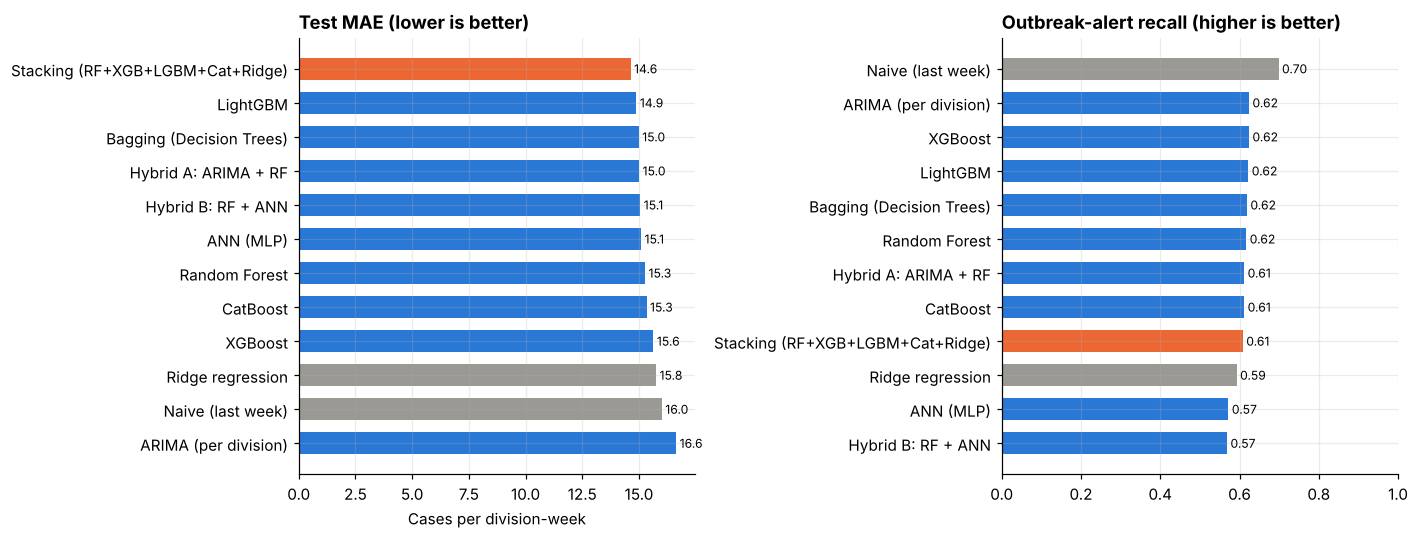

In [22]:
order = res.sort_values("MAE", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cols = [ORANGE if m == best_name else (GREY if f in ("Baseline",) else BLUE) for m, f in zip(order.model, order.family)]
axes[0].barh(order.model, order.MAE, color=cols, height=0.65)
axes[0].set_title("Test MAE (lower is better)", loc="left", fontweight="bold"); axes[0].set_xlabel("Cases per division-week")
for y, v in enumerate(order.MAE): axes[0].text(v, y, f" {v:.1f}", va="center", fontsize=8)
order2 = res.sort_values("Alert_Recall")
cols2 = [ORANGE if m == best_name else (GREY if f == "Baseline" else BLUE) for m, f in zip(order2.model, order2.family)]
axes[1].barh(order2.model, order2.Alert_Recall, color=cols2, height=0.65)
axes[1].set_title("Outbreak-alert recall (higher is better)", loc="left", fontweight="bold"); axes[1].set_xlim(0, 1)
for y, v in enumerate(order2.Alert_Recall): axes[1].text(v, y, f" {v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig("results/figures/model_comparison.png", dpi=150); plt.show()

**Error by period** — normal years vs the 2026 outbreak:

In [23]:
period = np.where(test["start_date"].dt.year == 2026, "2026 (outbreak)", test["start_date"].dt.year.astype(str))
per = {}
for m in res.model:
    e = np.abs(y_test.values - preds[m])
    per[m] = pd.Series(e).groupby(period).mean()
per = pd.DataFrame(per).T.round(2).loc[res.model]
per

,2024,2025,2026 (outbreak)
Stacking (RF+XGB+LGBM+Cat+Ridge),9.11,8.21,34.04
LightGBM,9.43,8.54,34.05
Bagging (Decision Trees),9.42,8.52,34.55
Hybrid A: ARIMA + RF,9.82,8.37,34.23
Hybrid B: RF + ANN,9.28,8.70,34.78
ANN (MLP),9.18,8.32,35.71
Random Forest,9.35,8.39,36.06
CatBoost,9.52,8.34,36.14
XGBoost,9.03,8.31,38.28
Ridge regression,9.58,9.00,36.76


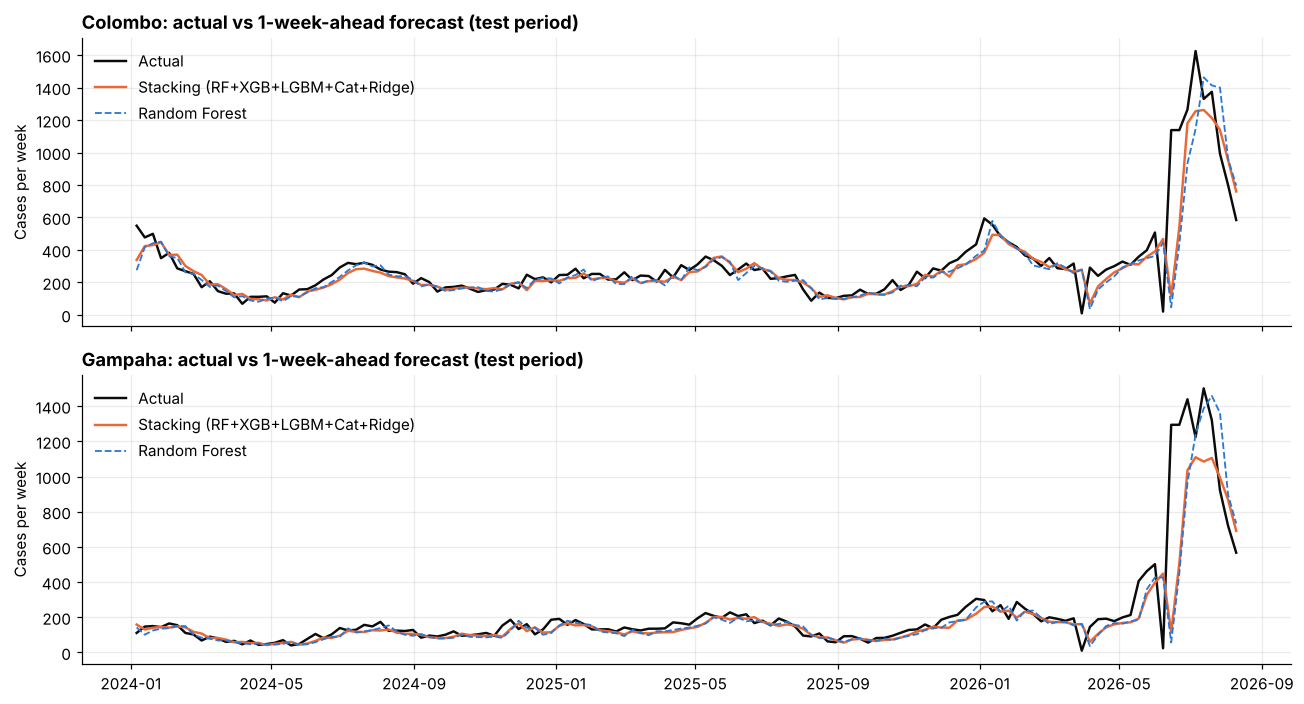

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, dname in zip(axes, ["Colombo", "Gampaha"]):
    m = test["district"] == dname
    ax.plot(test.loc[m, "start_date"], y_test[m], color="#0b0b0b", lw=1.6, label="Actual")
    ax.plot(test.loc[m, "start_date"], preds[best_name][m], color=ORANGE, lw=1.6, label=best_name)
    ax.plot(test.loc[m, "start_date"], preds["Random Forest"][m], color=BLUE, lw=1.2, ls="--", label="Random Forest")
    ax.set_title(f"{dname}: actual vs 1-week-ahead forecast (test period)", loc="left", fontweight="bold")
    ax.set_ylabel("Cases per week"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig("results/figures/actual_vs_pred.png", dpi=150); plt.show()

## 15. Why the models behaved this way

### 15.1 Overall result

| Rank by MAE | Model | MAE | RMSE | R² | Alert recall |
|---|---|---|---|---|---|
| 1 | **Stacking (RF+XGB+LGBM+Cat+Ridge)** | **14.63** | 49.86 | 0.814 | 0.608 |
| 2 | LightGBM | 14.89 | 50.21 | 0.811 | 0.622 |
| 3 | Bagging (Decision Trees) | 14.99 | 50.79 | 0.807 | 0.619 |
| 4 | Hybrid A: ARIMA + RF | 15.01 | 48.95 | 0.821 | 0.612 |
| 5 | Hybrid B: RF + ANN | 15.06 | **48.02** | **0.827** | 0.568 |
| … | Naive (last week) | 16.01 | 53.50 | 0.786 | **0.698** |
| last | ARIMA (per division) | 16.64 | 57.34 | 0.754 | 0.624 |

- **Stacking is the best model on MAE.** It is 8.6% better than the naive rule (16.01 → 14.63) and 4.2% better than a single Random Forest.
- **Hybrid B (RF + ANN) has the lowest RMSE and the highest R².** It makes fewer very large misses, which is useful during an outbreak.
- **No model beats the naive rule on outbreak recall** (0.70 vs about 0.61). This is explained in 15.6.
- The gap between the top nine models is small (14.6 to 15.6 cases). This is normal for this data: last week's count already explains most of this week's count (autocorrelation 0.83), so every good model starts from the same strong signal and the ensembles fight over the remaining part.

### 15.2 Why stacking won

The meta-learner weights were Ridge 0.42, LightGBM 0.27, XGBoost 0.13, CatBoost 0.13, RF 0.05. Ridge is the weakest model on its own, yet it gets the largest weight. The reason is **diversity**: the four tree ensembles make very similar mistakes, while the linear model makes *different* mistakes (it gives smooth, straight-line answers and can go above the largest value seen in training). Combining models that disagree cancels part of the error. This is the main idea of stacking from the lecture — heterogeneous base learners, combined by another model instead of a simple vote. Stacking was also the slowest model (55 s, because every base model is trained 6 times), which is acceptable for a weekly forecast.

### 15.3 Bagging vs Random Forest — the ρ term in practice

In theory Random Forest should beat plain Bagging because feature sampling reduces the correlation ρ between trees. Here **Bagging (14.99) was slightly better than Random Forest (15.27)**, and the measured tree correlation was almost the same (RF 0.927, Bagging 0.924). The reason is in the features: `lag1`, `lag2`, `roll_mean4` and `roll_mean8` all describe the *recent level* of cases and are highly correlated with each other. When a tree is given a random 60% of the features, it almost always still gets one of these, so the trees still look alike and ρ hardly falls. Grid search also preferred `max_features = 0.6` over `0.33`: forcing more randomness removed the strong predictors too often and increased bias more than it reduced variance. So the lecture formula holds — RF only helps when the random feature subsets really change the trees.

### 15.4 Boosting: LightGBM > CatBoost > XGBoost

- **LightGBM** was the best single model (MAE 14.89, trained in under 1 s). Leaf-wise growth lets it build deeper splits only where the data needs them — for example big divisions in outbreak weeks — while keeping other parts of the tree simple.
- **CatBoost** (15.33) used `district` and `season` as raw text. Native categorical handling did not give a big gain here because there are only 26 divisions and the lag features already tell the model how big each division is.
- **XGBoost** (15.63) was the weakest booster, and its error in the 2026 outbreak was the highest of the tree models (38.3). Its time-series CV chose shallow trees (depth 4) with a small learning rate (0.03) and 300 trees. This setting was safest on the older folds, but it is too conservative for the very large 2026 peaks — the sequential corrections stop before they reach the peak (high bias). The staged-error curve in Section 10 shows the error still falling slowly at the last tree.

So on this data boosting (LightGBM) beat bagging (RF) on bias, but only when the trees were allowed enough capacity.

### 15.5 Hybrids and ARIMA

- **ARIMA alone was the worst model** (MAE 16.64; 40.9 in 2026). It is linear, sees only one division at a time and cannot use national information or the monsoon season.
- **Hybrid A (ARIMA + RF)** cut ARIMA's error by 9.8% (16.64 → 15.01) and had the second-lowest RMSE. ARIMA follows each division's own level; the Random Forest learned the non-linear part ARIMA left behind — island-wide outbreaks (`nat_lag1`) and sudden rises. This confirms the idea of the hybrid: each part fixes what the other misses.
- **Hybrid B (RF + ANN)** had the best RMSE (48.0) and R² (0.827). The RF out-of-bag prediction gives the ANN a strong starting point, and the ANN's smooth output can move above the step-shaped RF values during peaks. It was slightly worse on MAE because the ANN is a little noisy in small, quiet divisions.

### 15.6 Normal years vs the 2026 outbreak

Error by period (MAE): 2024 ≈ 9–10, 2025 ≈ 8–9, but **2026 ≈ 34–41** for every model. All models are good in normal years and much worse in the outbreak. Two reasons, both visible in the Colombo and Gampaha plots:
1. **The forecasts react one week late.** The features are only past case counts, so a model cannot see the jump from about 500 to 1,130 cases in Colombo coming; it follows it a week later. Rainfall and flooding data would be needed to see an outbreak *before* cases rise.
2. **Trees cannot go beyond the training range and the log target pulls forecasts down.** Predicting `log(1+cases)` and converting back gives a value near the median, not the mean, so peaks are under-predicted. This is why the naive rule, which simply copies last week's high number, has the best outbreak recall. Ensembles are more accurate on average but more cautious at the top.

In 2026 the best ensembles (stacking, LightGBM: about 34.0) were still 8% better than the naive rule (36.9) and 17% better than ARIMA (40.9).

## 16. Feature importance

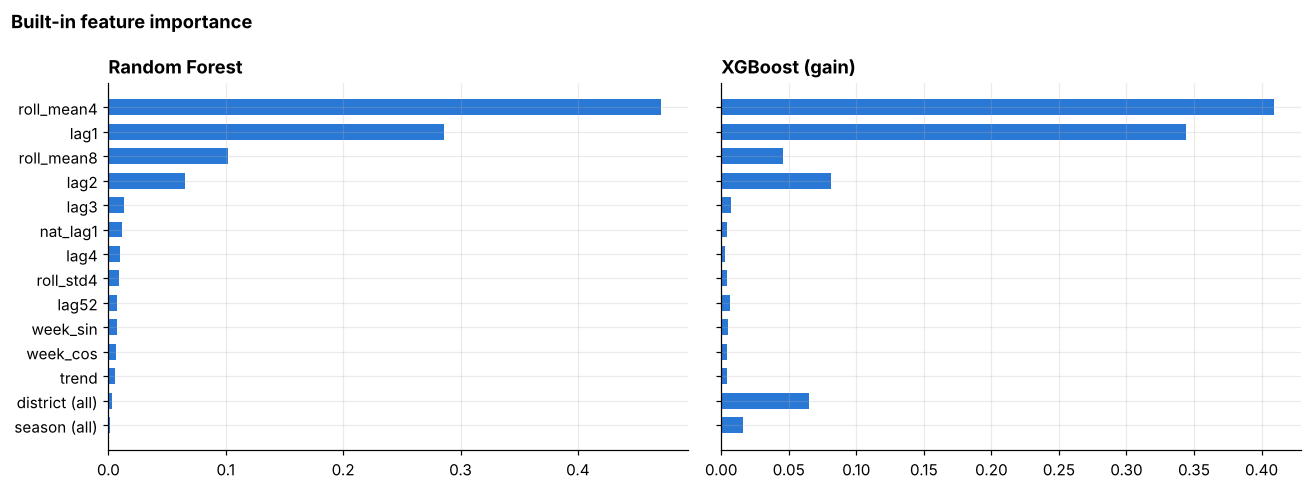

In [25]:
names = rf.regressor_.named_steps["prep"].get_feature_names_out()
imp_rf = pd.Series(rf.regressor_.named_steps["model"].feature_importances_, index=names)
imp_xgb = pd.Series(xgb.regressor_.named_steps["model"].feature_importances_, index=names)
def collapse(s):   # add up the one-hot district / season columns
    g = s.groupby(lambda c: "district (all)" if c.startswith("district_") else ("season (all)" if c.startswith("season_") else c))
    return g.sum().sort_values()
imp = pd.DataFrame({"Random Forest": collapse(imp_rf), "XGBoost (gain)": collapse(imp_xgb)}).sort_values("Random Forest")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, c in zip(axes, imp.columns):
    ax.barh(imp.index, imp[c], color=BLUE, height=0.65); ax.set_title(c, loc="left", fontweight="bold")
plt.suptitle("Built-in feature importance", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig("results/figures/feature_importance.png", dpi=150); plt.show()

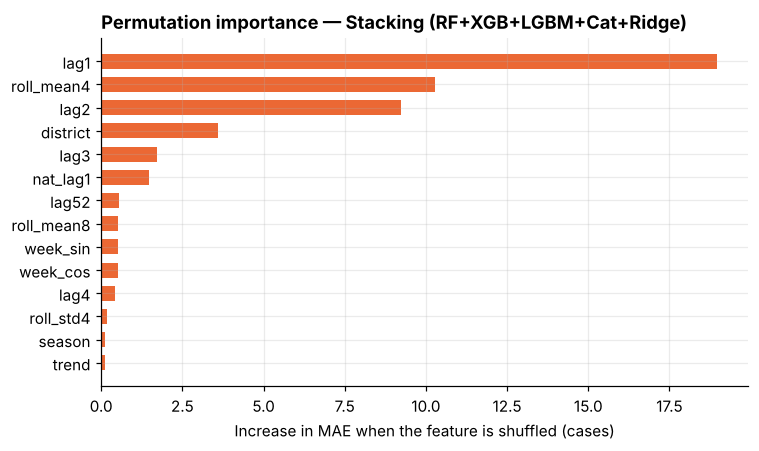

lag1          18.97
roll_mean4    10.29
lag2           9.22
district       3.60
lag3           1.73
nat_lag1       1.47
lag52          0.55
roll_mean8     0.52
week_sin       0.51
week_cos       0.51
lag4           0.43
roll_std4      0.19
season         0.12
trend          0.11
dtype: float64

In [26]:
best_model_obj = {"Random Forest": rf, "Bagging (Decision Trees)": bag, "XGBoost": xgb, "LightGBM": lgbm,
                  "CatBoost": cat, "Stacking (RF+XGB+LGBM+Cat+Ridge)": stack, "Hybrid B: RF + ANN": rf_ann,
                  "Ridge regression": ridge, "ANN (MLP)": ann}
perm_model_name = best_name if best_name in best_model_obj else "Stacking (RF+XGB+LGBM+Cat+Ridge)"
sample = test.sample(2000, random_state=SEED)
pi = permutation_importance(best_model_obj[perm_model_name], sample[FEATURES], sample[TARGET],
                            scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED, n_jobs=1)
perm = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(perm.index, perm.values, color=ORANGE, height=0.65)
ax.set_title(f"Permutation importance — {perm_model_name}", loc="left", fontweight="bold")
ax.set_xlabel("Increase in MAE when the feature is shuffled (cases)")
plt.tight_layout(); plt.savefig("results/figures/permutation_importance.png", dpi=150); plt.show()
perm.sort_values(ascending=False).round(2)

**What the importance results mean in the Sri Lankan context**

- **`lag1` and `roll_mean4` dominate** in every method (permutation: shuffling `lag1` adds about 19 cases to the MAE, `roll_mean4` about 10). Dengue spreads from person to mosquito to person in cycles of about two weeks, so the number of infected people in the last few weeks is the best guide to next week. For a PHI, this means the latest Weekly Epidemiological Report is the most valuable input — late reporting hurts the forecast directly.
- **`district` is the next most useful** (≈3.6 cases). Divisions have very different baselines: Colombo and Gampaha are dense urban areas with many breeding sites (construction sites, blocked drains, discarded containers), while Mannar or Mullaitivu have few cases.
- **`nat_lag1` (national total) adds about 1.5 cases** — when the whole island is in an outbreak, each division is more likely to rise as well (people travel between Colombo and their home towns).
- **Season and week of year matter less than expected.** The monsoon pattern is real (Section 5), but its effect already shows up in the recent case counts, so the model gains little from knowing the calendar. Real rainfall data would carry *earlier* information than the calendar and is the main improvement for future work.

## 17. Research reflection — RF vs gradient boosting, and tabular vs image/text data

### Random Forest vs XGBoost / LightGBM / CatBoost

| Aspect | Random Forest (bagging) | XGBoost / LightGBM / CatBoost (boosting) |
|---|---|---|
| How trees are built | Independent, in parallel, deep trees on bootstrap samples | One after another, small trees, each fixes the previous errors |
| Main error reduced | Variance (averaging de-correlated trees) | Bias (step-by-step fitting of residuals) |
| Overfitting risk | Low — more trees never hurt | Higher — needs learning rate, depth, early stopping, regularisation |
| Tuning effort | Small (2–3 key parameters) | Larger (learning rate, depth, n_estimators, subsample, …) |
| Speed | Parallel, but deep trees make large model files | LightGBM fastest; XGBoost fast; CatBoost slower to train but good defaults |
| Categorical features | Need encoding | XGBoost/LightGBM need encoding (or special mode); **CatBoost handles text categories natively** |
| Extrapolation | Cannot predict above the largest training value | Same limitation (also tree-based) |

### Strengths and limitations on tabular vs image / text data

**Tabular data (like this project).** Tree ensembles are still the strongest general choice for medium-sized tables with
mixed numeric and categorical columns. Large benchmark studies (Grinsztajn et al., 2022; Shwartz-Ziv & Armon, 2022) found
that XGBoost-type models usually match or beat deep networks on tabular data while being cheaper to train and easier to tune.
They handle different feature scales, missing values (XGBoost/LightGBM) and non-linear interactions without much
preprocessing, and they give feature importances that health officers can understand.

**Image and text data.** Here ensembles of trees are weak. A pixel or a single word means little on its own; meaning comes
from local patterns (edges, shapes, word order, context). Trees split on one raw feature at a time and cannot learn these
spatial or sequential patterns. CNNs, transformers and LLMs learn the representation directly and win clearly. Tree ensembles
are still useful on top of extracted features (for example, gradient boosting on CNN embeddings or TF-IDF vectors), and
ensembling *of neural networks* (averaging several CNNs) is common.

**Lesson for this project (also from the lecture):** a costly deep-learning or LLM model is not needed for a weekly
count forecast. A well-built ensemble of trees is cheaper, faster and easier to explain — the right tool for the job.

## 18. Saving models and next-week early warning

All trained models are saved with `joblib` (`.pkl`) so that the Streamlit dashboard loads them instantly. The test-set
predictions, metrics and division thresholds are also saved. Then we build features for the **week after the last week in
the data** and forecast every division — this is the early-warning table shown on the dashboard.

In [27]:
to_save = {"random_forest": rf, "bagging": bag, "xgboost": xgb, "lightgbm": lgbm, "catboost": cat,
           "stacking": stack, "ridge": ridge, "ann": ann, "rf_ann_hybrid": rf_ann,
           "arima_rf_hybrid": {"rf_resid": rf_resid, "arima": {k: {"order": v["order"], "params": v["params"]} for k, v in arima_fit.items()}}}
for k, m in to_save.items():
    joblib.dump(m, f"models/{k}.pkl", compress=3)
sizes = {f: round(os.path.getsize(f"models/{f}") / 1e6, 1) for f in sorted(os.listdir("models"))}
print("Saved model files (MB):", sizes)

res.to_csv("results/model_comparison.csv", index_label="rank")
per.to_csv("results/error_by_period.csv")
thr.to_csv("results/division_thresholds.csv")
out = test[["start_date", "district", "epi_week", "cases"]].copy()
for m in res.model: out[m] = np.round(preds[m], 2)
out.to_csv("results/test_predictions.csv", index=False)
imp.to_csv("results/feature_importance.csv"); perm.to_csv("results/permutation_importance.csv")
json.dump({"best_model": best_name, "rho_rf": rho_rf, "rho_bag": rho_bag,
           "best_rf": best_rf, "best_xgb": {k: (float(v) if not isinstance(v, int) else v) for k, v in best_xgb.items()},
           "stack_weights": dict(zip(["RF", "XGB", "LGBM", "CatBoost", "Ridge"], map(float, w))),
           "train_period": [str(train.start_date.min().date()), str(train.start_date.max().date())],
           "test_period": [str(test.start_date.min().date()), str(test.start_date.max().date())]},
          open("results/run_info.json", "w"), indent=2)

Saved model files (MB): {'ann.pkl': 0.1, 'arima_rf_hybrid.pkl': 14.0, 'bagging.pkl': 13.7, 'catboost.pkl': 0.3, 'lightgbm.pkl': 0.6, 'random_forest.pkl': 13.7, 'rf_ann_hybrid.pkl': 13.8, 'ridge.pkl': 0.0, 'stacking.pkl': 14.8, 'xgboost.pkl': 0.1}


In [28]:
from dengue_features import risk_level
last = df["start_date"].max()
nxt = df[df["start_date"] == last][["district"]].copy()
nxt["start_date"] = last + pd.Timedelta(days=7); nxt["epi_week"] = int(df.loc[df.start_date == last, "epi_week"].iloc[0]) + 1
nxt["cases"] = np.nan
fut = build_features(pd.concat([df[["start_date", "epi_week", "district", "cases"]], nxt]))
fut = fut[fut["start_date"] == nxt["start_date"].iloc[0]].reset_index(drop=True)
fc = fut[["start_date", "district", "epi_week"]].copy()
fc["last_week_cases"] = np.expm1(fut["lag1"]).round().astype(int)
for k, m in {"Random Forest": rf, "XGBoost": xgb, "LightGBM": lgbm, "CatBoost": cat,
             "Stacking (RF+XGB+LGBM+Cat+Ridge)": stack, "Hybrid B: RF + ANN": rf_ann}.items():
    fc[k] = np.round(m.predict(fut[FEATURES]), 1)
# Hybrid A: ARIMA one-step forecast + RF residual
fc["arima_log"] = [float(arima_fit[d]["result"].forecast(1).iloc[0]) for d in fc["district"]]
fut["arima_log"] = fc["arima_log"].values
fc["Hybrid A: ARIMA + RF"] = np.round(np.expm1(fc["arima_log"] + rf_resid.predict(fut[H_FEATURES])), 1)
fc = fc.drop(columns="arima_log")
fc["forecast"] = fc[best_name] if best_name in fc else fc["Stacking (RF+XGB+LGBM+Cat+Ridge)"]
fc["risk"] = [risk_level(p, thr.loc[d]) for p, d in zip(fc["forecast"], fc["district"])]
fc = fc.sort_values("forecast", ascending=False)
fc.to_csv("results/next_week_forecast.csv", index=False)
print("Forecast for week starting", fc.start_date.iloc[0].date(), "using", best_name)
fc[["district", "last_week_cases", "forecast", "risk"]].head(12)

Forecast for week starting 2026-08-17 using Stacking (RF+XGB+LGBM+Cat+Ridge)


,district,last_week_cases,forecast,risk
4,Colombo,584,612.6,Very high
6,Gampaha,567,546.6,Very high
11,Kandy,288,270.7,Very high
10,Kalutara,186,212.3,Very high
5,Galle,144,143.6,Very high
17,Matara,114,126.1,Very high
23,Ratnapura,92,112.6,Very high
14,Kurunegala,106,107.0,High
12,Kegalle,99,100.1,High
7,Hambantota,80,71.9,Very high


## 19. Dashboard

The interactive dashboard is in `app.py` (Streamlit). It loads the saved `.pkl` models and result files.

| Page | What it shows |
|---|---|
| **Overview** | dataset size, national weekly curve, division totals, seasonality |
| **Model comparison** | metrics table and bar charts for all models, best model marked, error by period |
| **Forecast explorer** | choose a division and a model → actual vs predicted over the test period |
| **Feature importance** | RF / XGBoost importance and permutation importance |
| **Next-week early warning** | ranked risk table for all 26 divisions for the week after the latest data |
| **Live prediction** | enter recent weekly counts for any division → forecasts from every saved model + risk level |

Run locally:
```bash
pip install -r requirements.txt
streamlit run app.py
```
Deployment to Streamlit Community Cloud is described in `README.md`.

## 20. Conclusion and limitations

**Conclusion.** This project built and compared 12 models for 1-week-ahead dengue forecasting in all 26 RDHS divisions of Sri Lanka using official Ministry of Health data (2007–2026).

- **Best overall: Stacking** (RF + XGBoost + LightGBM + CatBoost + Ridge) — MAE 14.63 cases per division-week, 8.6% better than the naive rule.
- **Best single model: LightGBM** — almost as accurate as stacking (14.89) and about 70 times faster to train.
- **Best for large errors: Hybrid B (RF + ANN)** — lowest RMSE (48.0) and highest R² (0.827).
- **Hybrid A (ARIMA + RF)** improved ARIMA by 9.8%, showing that tree ensembles add the non-linear part that a classic time-series model misses.
- Bagging and Random Forest performed about the same because the lag features are strongly correlated, so feature sampling did not reduce tree correlation.
- The dashboard turns the forecasts into a ranked risk table for all divisions.

**Limitations**
- Only past case counts are used. The models react one week after a sudden jump; they cannot predict the *start* of an outbreak.
- Weekly reports are provisional. Some weeks are incomplete (e.g. Colombo drops to almost zero for one week in March and June 2026), and the last four weeks had to be removed. These gaps add error.
- The log target under-predicts peaks, so outbreak-alert recall (≈0.61) is lower than the naive rule (0.70).
- Tree models cannot predict above the highest level seen in training.
- Tuning was light (small grids) to keep the notebook fast.

**Future work**
- Add rainfall and temperature from the Department of Meteorology, and flood reports from the DMC, as leading indicators.
- Forecast 2–4 weeks ahead and at MOH-division level.
- Use a count-based loss (Poisson / Tweedie in LightGBM or XGBoost) or a bias correction to reduce peak under-prediction.
- Tune the alert threshold to reach a target recall (e.g. 0.8) for public-health use.

## 21. AI Usage Acknowledgment

As allowed by the lecturer, Generative AI was used in this project. This section states exactly where.

| Part of the project | GenAI tool | How it was used |
|---|---|---|
| Data download/cleaning script (`download_data.py`) | Claude (Anthropic) | Code generated, then run and checked by me |
| Feature engineering module (`dengue_features.py`) | Claude (Anthropic) | Code generated; feature choices discussed and reviewed by me |
| Modelling code in this notebook (bagging, boosting, stacking, hybrids, evaluation, plots) | Claude (Anthropic) | Boilerplate and model code generated; results produced by running the notebook |
| Hybrid model class (`hybrid_models.py`) | Claude (Anthropic) | Code generated |
| Streamlit dashboard (`app.py`) | Claude (Anthropic) | Front-end code generated |
| Model re-save script (`fix_xgb_models.py`) | Claude (Anthropic) | Written with Claude Code to fix the XGBoost model loading error; run once to re-save models |
| Markdown explanations, README, video script, slides | Claude (Anthropic) | First drafts generated, then edited by me |

**Not generated by AI:** the dataset (official Ministry of Health data, via the denguedatahub package) and all numerical
results — every number in this notebook comes from running the code on the real data. I reviewed the code, the results and
the interpretation and I am responsible for the submitted work.

## 22. References

1. Epidemiology Unit, Ministry of Health, Sri Lanka. *Weekly Epidemiological Report* (2006–2026). https://www.epid.gov.lk
2. Talagala, T. S. *denguedatahub: A Tidy Format Datasets of Dengue by Country* (R package). https://github.com/thiyangt/denguedatahub
3. Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24, 123–140.
4. Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32.
5. Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5).
6. Chen, T. & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *KDD 2016*.
7. Ke, G. et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS 2017*.
8. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
9. Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.
10. Zhang, G. P. (2003). Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*, 50, 159–175.
11. Grinsztajn, L., Oyallon, E. & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on tabular data? *NeurIPS 2022 Datasets & Benchmarks*.
12. Shwartz-Ziv, R. & Armon, A. (2022). Tabular data: deep learning is not all you need. *Information Fusion*, 81, 84–90.
13. News reports on the 2026 outbreak: Reuters/The Star (19 Jun 2026), Newsfirst (11 Aug 2026), IFRC DREF Operation MDRLK024 (2026).